# 2. Pré-processamento das Imagens INbreast

## Objetivo
- Ler os arquivos DICOM preservando a intensidade original.
- Verificar a interpretação fotométrica (PhotometricInterpretation) e inverter se `MONOCHROME1`, garantindo que o tecido denso e as calcificações sejam estruturas de alta intensidade.
- Produzir uma máscara da mama para remover fundo e artefatos/textos.
- Criar versões para visualização com contraste ajustado (CLAHE), sem sobrescrever os dados originais.
- Aplicar testes em diferentes resoluções e registrar os parâmetros.
- Inspecionar visualmente os resultados.

In [1]:
import os
import cv2
import pydicom
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops
from skimage.morphology import closing, disk

## Carregando o Lote Inicial
Vamos carregar o manifesto gerado na etapa anterior.

In [2]:
manifest_path = Path('../../data/interim/inbreast_batch1_ml_manifest.csv')
df_batch = pd.read_csv(manifest_path)
df_batch.head()

,image_id,dcm_path,view,laterality,rows,columns,pixel_spacing_x,pixel_spacing_y
0,51049276,../../data/external/inbreast/raw/INbreast Rele...,ML,L,4084,3328,NaN,NaN
1,50996709,../../data/external/inbreast/raw/INbreast Rele...,ML,R,4084,3328,NaN,NaN
2,20587928,../../data/external/inbreast/raw/INbreast Rele...,ML,R,3328,2560,NaN,NaN
3,53587104,../../data/external/inbreast/raw/INbreast Rele...,ML,L,4084,3328,NaN,NaN
4,20588216,../../data/external/inbreast/raw/INbreast Rele...,ML,L,3328,2560,NaN,NaN


## Funções de Pré-processamento
Aqui definimos o pipeline: leitura do DICOM, correção de polaridade, segmentação da mama e realce de contraste visual.

In [3]:
def load_dicom_image(dcm_path):
    """Lê a imagem DICOM, preservando a intensidade e ajustando a polaridade."""
    ds = pydicom.dcmread(dcm_path)
    image = ds.pixel_array.astype(np.float32)
    
    # Tratamento de polaridade
    # MONOCHROME1: low values = bright, high values = dark. Precisamos inverter.
    # MONOCHROME2: low values = dark, high values = bright. Padrão desejado.
    photometric = getattr(ds, 'PhotometricInterpretation', 'UNKNOWN')
    if photometric == 'MONOCHROME1':
        image = np.max(image) - image
        
    # Normalização min-max para faixa 0-1 (Float) apenas para base do pipeline de imagem
    # Mas manteremos a versão bruta se precisarmos do valor original do pixel.
    image_normalized = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-8)
    
    return image, image_normalized, photometric


def create_breast_mask(image_normalized):
    """
    Gera máscara da mama para remover fundo, bordas e textos.
    Utiliza limiarização de Otsu e mantém o maior componente conexo.
    """
    # Suavização leve para remover ruídos pequenos
    img_blur = cv2.GaussianBlur(image_normalized, (5, 5), 0)
    
    # Threshold de Otsu
    # Ignoramos os pixels absolutamente zeros (fundo escuro puro)
    pixels = img_blur[img_blur > 0.05]
    if len(pixels) == 0:
        return np.zeros_like(img_blur, dtype=bool)
        
    thresh = threshold_otsu(pixels)
    binary = img_blur > thresh
    
    # Fechamento morfológico para conectar pequenas falhas
    binary = closing(binary, disk(5))
    
    # Manter apenas o maior componente conexo (a mama)
    label_img = label(binary)
    regions = regionprops(label_img)
    
    if not regions:
         return binary
         
    # Encontrar a região com maior área
    largest_region = max(regions, key=lambda r: r.area)
    
    mask = (label_img == largest_region.label)
    return mask

def enhance_visualization(image_normalized, mask):
    """
    Aplica CLAHE apenas para visualização. 
    Retorna versão em uint8.
    """
    # Aplicar a máscara antes do CLAHE para o fundo não influenciar
    img_masked = image_normalized.copy()
    img_masked[~mask] = 0
    
    # Converter para uint16 para o CLAHE do OpenCV (ou uint8)
    img_uint8 = (img_masked * 255).astype(np.uint8)
    
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_enhanced = clahe.apply(img_uint8)
    return img_enhanced

## Testando o Pipeline no Lote
Vamos processar e visualizar as imagens do lote.

Processando imagem: 51049276 | Polaridade original será impressa no plot


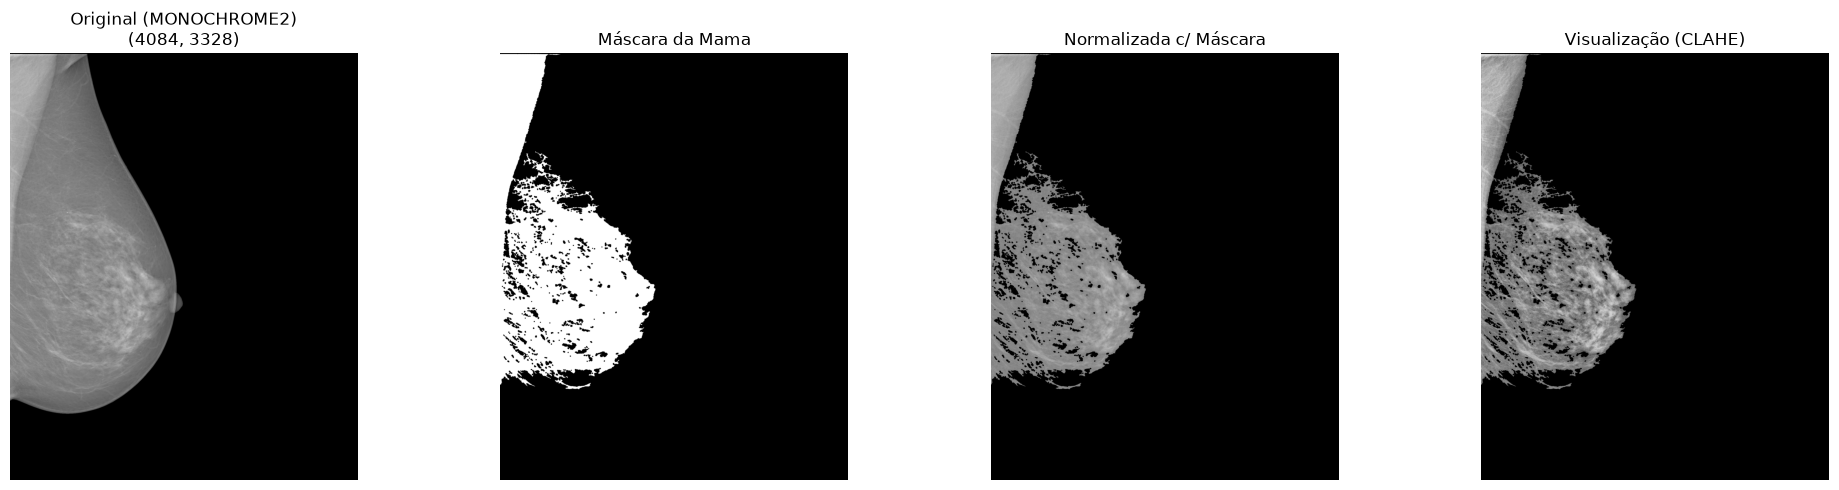

Processando imagem: 50996709 | Polaridade original será impressa no plot


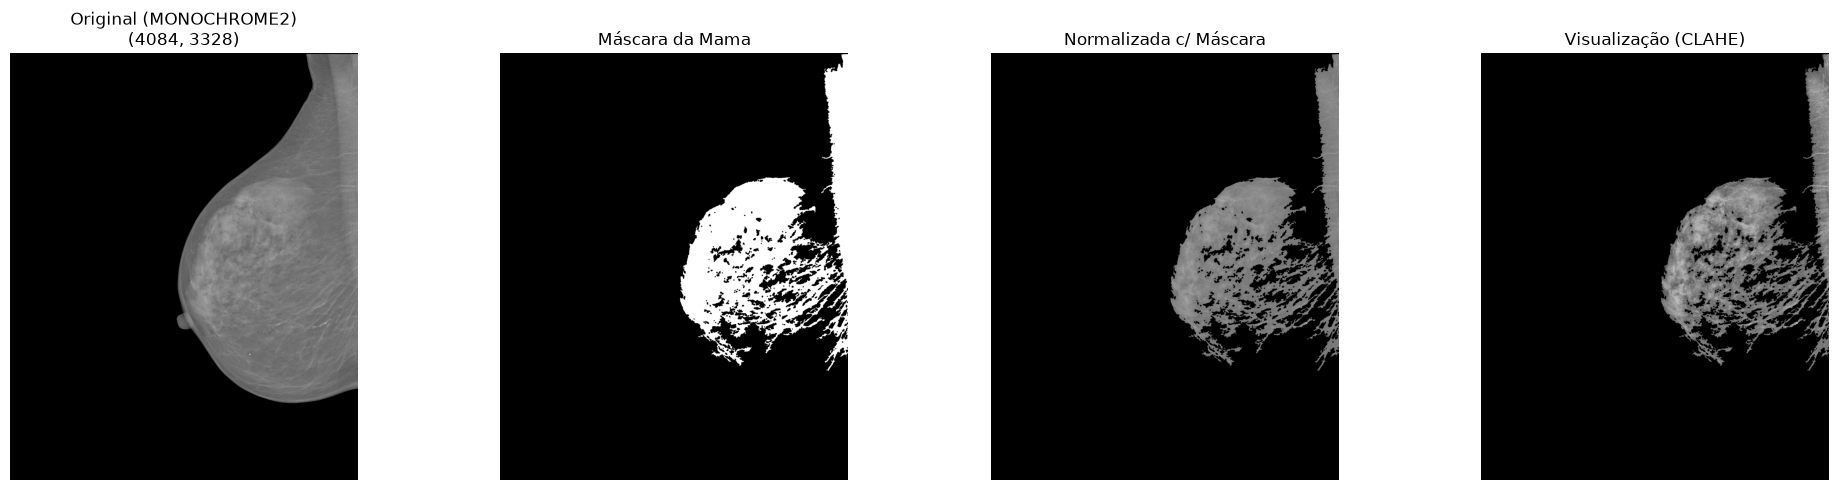

Processando imagem: 20587928 | Polaridade original será impressa no plot


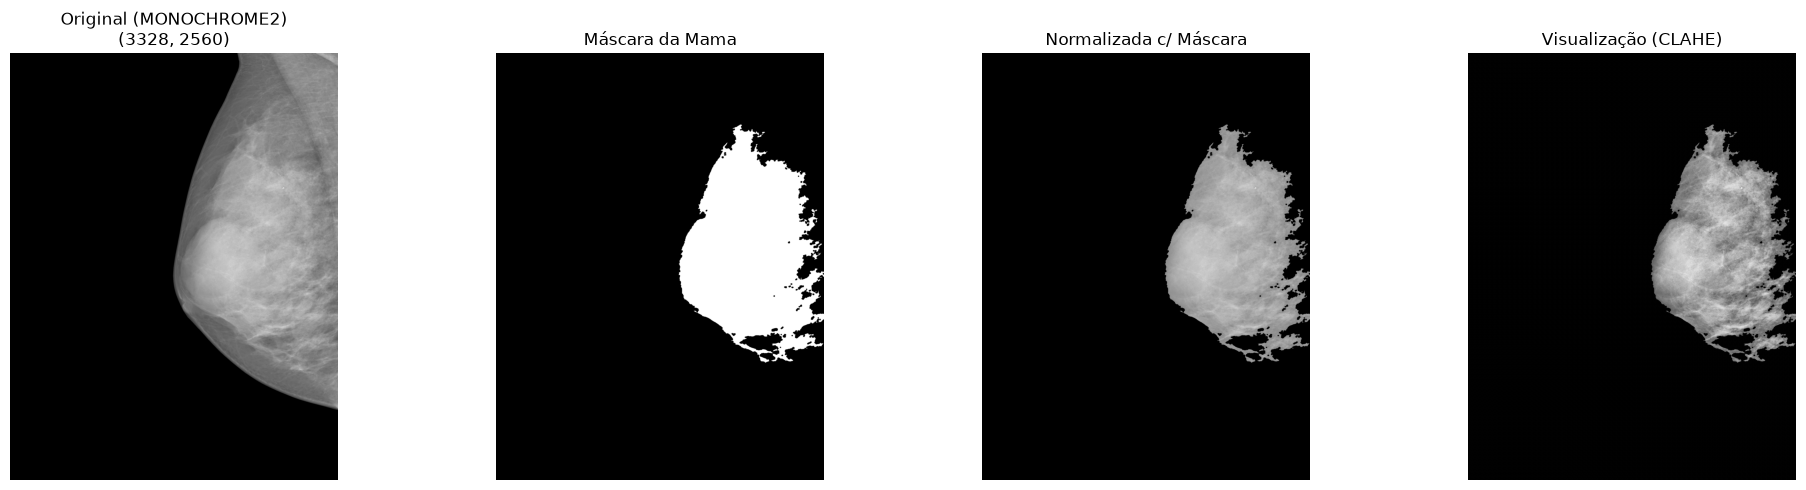

Processando imagem: 53587104 | Polaridade original será impressa no plot


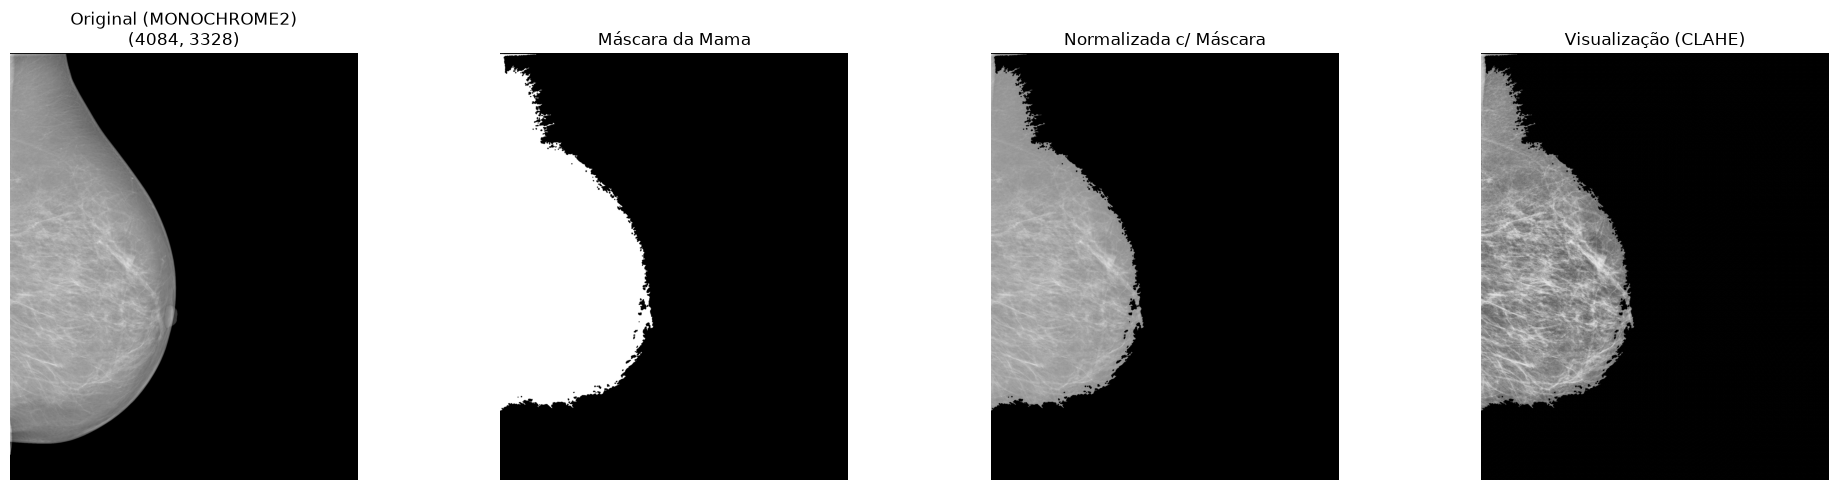

Processando imagem: 20588216 | Polaridade original será impressa no plot


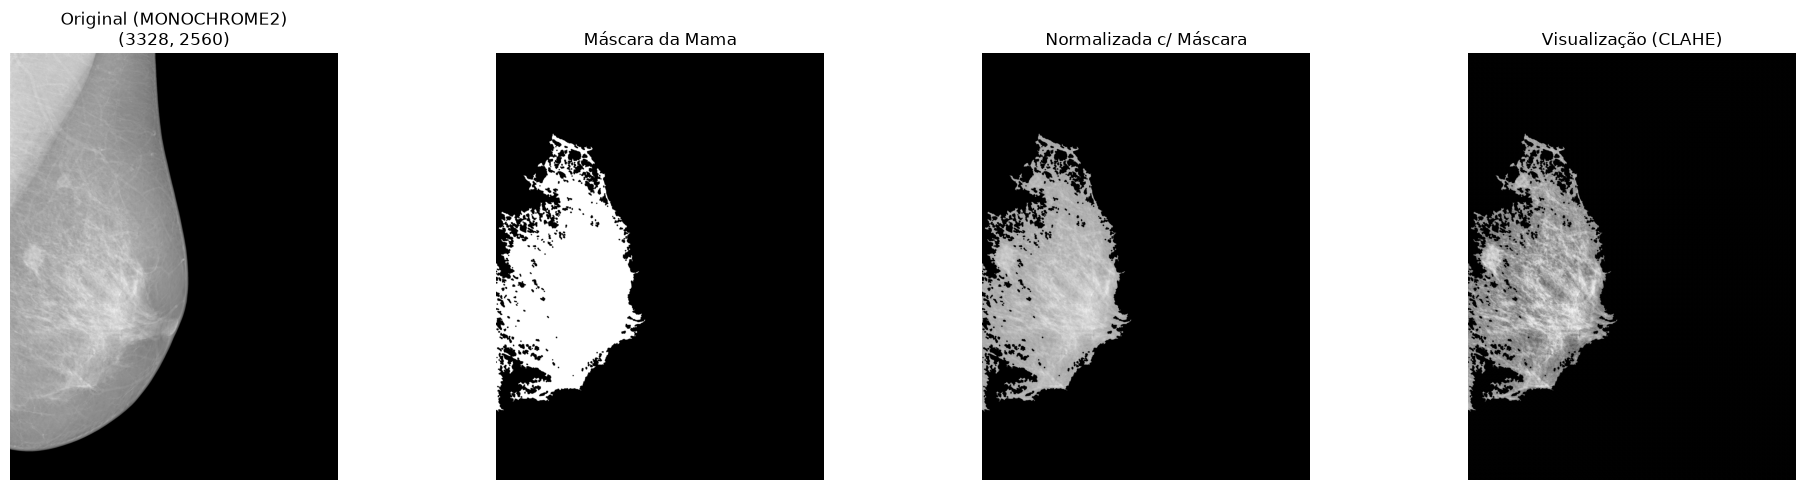

In [4]:
# Vamos armazenar informações de escala (resoluções)
scaling_records = []

for idx, row in df_batch.iterrows():
    print(f"Processando imagem: {row['image_id']} | Polaridade original será impressa no plot")
    
    # 1. Carregar DICOM preservando a intensidade bruta
    img_raw, img_norm, photo_interp = load_dicom_image(row['dcm_path'])
    
    # 2. Criar máscara da mama
    mask = create_breast_mask(img_norm)
    
    # 3. Gerar imagem para visualização (com contraste ajustado)
    img_vis = enhance_visualization(img_norm, mask)
    
    # Aplicando a máscara à imagem normalizada
    img_processed = img_norm.copy()
    img_processed[~mask] = 0
    
    # Teste de resolução (Redimensionamento de depuração)
    # Target comum para modelos baseados em Transformers é 1024x1024
    target_size = (1024, 1024)
    original_shape = img_processed.shape
    img_resized = cv2.resize(img_processed, target_size, interpolation=cv2.INTER_AREA)
    
    scaling_records.append({
        'image_id': row['image_id'],
        'original_height': original_shape[0],
        'original_width': original_shape[1],
        'target_height': target_size[0],
        'target_width': target_size[1],
        'scale_y': target_size[0] / original_shape[0],
        'scale_x': target_size[1] / original_shape[1]
    })
    
    # 4. Inspecionar visualmente as saídas intermediárias
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    axes[0].imshow(img_raw, cmap='gray')
    axes[0].set_title(f"Original ({photo_interp})\n{original_shape}")
    axes[0].axis('off')
    
    axes[1].imshow(mask, cmap='gray')
    axes[1].set_title("Máscara da Mama")
    axes[1].axis('off')
    
    axes[2].imshow(img_processed, cmap='gray')
    axes[2].set_title("Normalizada c/ Máscara")
    axes[2].axis('off')
    
    axes[3].imshow(img_vis, cmap='gray')
    axes[3].set_title("Visualização (CLAHE)")
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.show()

## Registro de Redimensionamento
Salvando informações de redimensionamento para converter coordenadas posteriormente.

In [5]:
df_scales = pd.DataFrame(scaling_records)
scales_path = Path('../../data/interim/inbreast_batch1_scaling.csv')
df_scales.to_csv(scales_path, index=False)

print("Tabela de conversão de escala:")
display(df_scales)

Tabela de conversão de escala:


,image_id,original_height,original_width,target_height,target_width,scale_y,scale_x
0,51049276,4084,3328,1024,1024,0.250735,0.307692
1,50996709,4084,3328,1024,1024,0.250735,0.307692
2,20587928,3328,2560,1024,1024,0.307692,0.400000
3,53587104,4084,3328,1024,1024,0.250735,0.307692
4,20588216,3328,2560,1024,1024,0.307692,0.400000
